# Диагностика колоректального рака по микробиому кишечника (Genotek)
## 1. Литература (п. 4.2.1)
Решение опирается на 4 метаанализа метагеномов кала при КРР: **Zeller et al. (2014)**, **Wirbel et al. (2019)**, **Thomas et al. (2019)** и **Piccinno et al. (2025)**. 
- **Биологическая база:** каскад $APC \to KRAS \to TP53$, истончение муцинового слоя, колонизация толстой кишки оральными патобионтами (*Fusobacterium nucleatum, Parvimonas micra, Peptostreptococcus stomatis, Gemella morbillorum, Porphyromonas*) и одновременный дефицит защитных бутират-продуцентов (*Faecalibacterium prausnitzii, Roseburia, Coprococcus, Anaerostipes, Ruminococcus bromii*).
- **«Немые» (Fusobacterium-негативные) случаи:** у 25–30% пациентов (характерно для США) отсутствует яркая оральная транслокация, что требует учёта маркеров мукозального воспаления (*Ruminococcus gnavus, Ruminococcus torques, Bacteroides fragilis, Clostridium leptum/boltae*). Мировой бенчмарк переносимого ROC AUC: 0.81–0.85.


In [1]:
import os
import random
from pathlib import Path
from IPython.display import display

SEED = 42
SEEDS = [42, 100, 2026, 7]

os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold
try:
    from catboost import CatBoostClassifier, Pool
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "catboost"])
    from catboost import CatBoostClassifier, Pool

random.seed(SEED)
np.random.seed(SEED)



Среда настроена. Глобальный SEED = 42, сиды ансамбля = [42, 100, 2026, 7]


## 2. Признаки, предобработка и отбор фичей (п. 4.2.2, 4.2.3)
- **Предобработка:** Перевод сырых прочтений в относительные доли $P = X / \sum X$ для полного устранения технической утечки глубины секвенирования (`library_size`).
- **CLR-преобразование:** Вычисление $\text{CLR} = \ln(X + \varepsilon) - \text{mean}(\ln(X + \varepsilon))$ с адаптивным псевдосчётом $\varepsilon = 0.5 \cdot \min(X_{ref} > 0)$.
- **Биологические гильдии:** Суммарные доли оральной, бутиратной (с включением *R. bromii*), муцинолитической и факультативной групп; индексы дисбиоза $\ln(\text{Oral}) - \ln(\text{Butyrate})$, соотношение оральных видов к общему богатству; $\alpha$-разнообразие (Шеннон, Симпсон, Richness).
- **Отбор признаков:** Расчёт эффекта каждого таксона (AUC - 0.5) раздельно по 5 когортам. Отбор топ-70 видов по устойчивости знака эффекта: $\text{Score} = |\mu| - 0.20\sigma$ с фильтром распространённости $\ge 6$ ненулевых образцов.


In [2]:
def find_data_files():
    """Автоматический поиск train.csv и test.csv в директориях проекта и среды."""
    search_roots = [".", "..", "/kaggle", "/content", "/data", "/workspace", "/home", "/tmp"]
    for base in search_roots:
        if not os.path.exists(base):
            continue
        for root, _, files in os.walk(base):
            if "train.csv" in files and "test.csv" in files:
                return Path(root) / "train.csv", Path(root) / "test.csv"
    raise FileNotFoundError("Не удалось найти train.csv и test.csv в доступных директориях.")


train_path, test_path = find_data_files()
print(f"Загружаем данные из: {train_path.parent}")

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

TAXA_COLS = [c for c in train_df.columns if "mOTU_v2_" in c]

print(f"Размер train.csv: {train_df.shape} | Размер test.csv: {test_df.shape}")
print(f"Число таксономических признаков mOTU: {len(TAXA_COLS)}\n")

print("Распределение классов (label) по когортам в train.csv:")
display(pd.crosstab(train_df["cohort"], train_df["label"], margins=True))

print("\nСравнение возраста и глубины секвенирования (Case vs Control):")
for c, g in train_df.groupby("cohort"):
    case_age = g.loc[g["label"] == 1, "age"].mean()
    ctrl_age = g.loc[g["label"] == 0, "age"].mean()
    case_lib = g.loc[g["label"] == 1, "library_size"].median() / 1e6
    ctrl_lib = g.loc[g["label"] == 0, "library_size"].median() / 1e6
    print(f"  {c:3s}: Case Age={case_age:.1f}, Ctrl Age={ctrl_age:.1f} | "
          f"Case Depth={case_lib:.1f}M, Ctrl Depth={ctrl_lib:.1f}M")

species_names = np.array([c.split(" [")[0].replace("unknown ", "") for c in TAXA_COLS])
genera = np.array([s.split()[0] for s in species_names])

ORAL_GENERA = {
    "Fusobacterium", "Parvimonas", "Peptostreptococcus", "Porphyromonas",
    "Gemella", "Dialister", "Hungatella", "Solobacterium", "Prevotella",
    "Campylobacter", "Treponema", "Selenomonas", "Veillonella"
}
BUTYRATE_GENERA = {
    "Faecalibacterium", "Roseburia", "Coprococcus", "Anaerostipes",
    "Butyricicoccus", "Eubacterium", "Subdoligranulum"
}
MUCIN_BILE_GENERA = {"Akkermansia", "Bilophila", "Ruminococcus"}
FACULTATIVE_GENERA = {"Escherichia", "Klebsiella", "Citrobacter", "Enterococcus", "Enterobacter"}

is_bromii = np.array(["ruminococcus bromii" in s.lower() for s in species_names])
buty_mask = np.isin(genera, list(BUTYRATE_GENERA)) | is_bromii
mucin_mask = np.isin(genera, list(MUCIN_BILE_GENERA)) & (~is_bromii)
oral_mask = np.isin(genera, list(ORAL_GENERA))
fac_mask = np.isin(genera, list(FACULTATIVE_GENERA))

BIOMARKER_TERMS = [
    "Parvimonas micra", "Fusobacterium nucleatum", "Gemella morbillorum",
    "Peptostreptococcus stomatis", "Dialister", "Solobacterium moorei",
    "Porphyromonas asaccharolytica", "Hungatella hathewayi",
    "Faecalibacterium prausnitzii", "Roseburia intestinalis", "Anaerostipes hadrus",
    "Ruminococcus torques", "Bacteroides fragilis", "Clostridium scindens",
    "Clostridium symbiosum", "Streptococcus gallolyticus", "Bilophila wadsworthia",
    "Akkermansia muciniphila", "Escherichia coli", "Ruminococcus gnavus", "Clostridium leptum"
]
MATCHED_BIO_TERMS = [
    t for t in BIOMARKER_TERMS
    if any(t.lower() in name.lower() for name in species_names)
]

USA_SPEC_TERMS = [
    "Bacteroides fragilis", "Ruminococcus gnavus", "Clostridium leptum",
    "Clostridium boltae", "Clostridium symbiosum", "Ruminococcus torques",
    "Oscillibacter", "Butyricicoccus", "Enterobacteriaceae"
]
MATCHED_USA_TERMS = [
    t for t in USA_SPEC_TERMS
    if any(t.lower() in name.lower() for name in species_names)
]

usa_spec_idx = [i for i, c in enumerate(TAXA_COLS) if any(term.lower() in c.lower() for term in MATCHED_USA_TERMS)]


def select_consistent_taxa(X_taxa, cohorts, y, top_k=70):
    """Отбор таксонов со стабильным направлением эффекта по всем когортам."""
    effects = []
    for c in sorted(set(cohorts)):
        mask = (cohorts == c)
        c_X = X_taxa[mask]
        c_y = (y[mask] == 1)
        ranks = rankdata(c_X, axis=0)
        n_pos = c_y.sum()
        n_neg = (~c_y).sum()
        if n_pos > 0 and n_neg > 0:
            auc = (ranks[c_y].sum(axis=0) - n_pos * (n_pos + 1) / 2.0) / (n_pos * n_neg)
            effects.append(auc - 0.5)
    effects = np.stack(effects)
    consistency = np.abs(effects.mean(axis=0)) - 0.20 * effects.std(axis=0)
    consistency[(X_taxa > 0).sum(axis=0) < 6] = -999.0
    return np.argsort(-consistency)[:top_k]


def build_features(df, ref_df, selected_taxa_idx, is_usa_engine=False):
    """Формирование чистых биологических признаков для Global Engine и USA Specialist."""
    X = df[TAXA_COLS].values.astype(float)
    X_ref = ref_df[TAXA_COLS].values.astype(float)

    row_sum = np.maximum(X.sum(axis=1, keepdims=True), 1e-9)
    P = X / row_sum

    pos_min = X_ref[X_ref > 0].min() if (X_ref > 0).any() else 1e-6
    pseudo = 0.5 * pos_min

    oral_abund = P[:, oral_mask].sum(axis=1)
    buty_abund = P[:, buty_mask].sum(axis=1)
    mucin_abund = P[:, mucin_mask].sum(axis=1)
    fac_abund = P[:, fac_mask].sum(axis=1)

    oral_cnt = (X[:, oral_mask] > 0).sum(axis=1)
    buty_cnt = (X[:, buty_mask] > 0).sum(axis=1)
    richness = (X > 0).sum(axis=1)

    shannon = -np.sum(np.where(P > 0, P * np.log(np.maximum(P, 1e-9)), 0), axis=1)
    simpson = 1.0 - np.sum(P ** 2, axis=1)

    dysbiosis_1 = np.log(oral_abund + pseudo) - np.log(buty_abund + pseudo)
    dysbiosis_2 = np.log(oral_abund + mucin_abund + fac_abund + pseudo) - np.log(buty_abund + pseudo)
    oral_ratio = oral_cnt / (richness + 1.0)

    ref_bmi = ref_df["bmi"].median()
    gender_m = (df["gender"] == "M").values.astype(float)
    bmi = df["bmi"].fillna(ref_bmi).values.astype(float)

    if not is_usa_engine:
        age = df["age"].values.astype(float)
        age_dys = age * dysbiosis_1
        age_oral = age * np.log(oral_abund + pseudo)

        bio_cols = []
        for term in MATCHED_BIO_TERMS:
            matches = [i for i, name in enumerate(species_names) if term.lower() in name.lower()]
            bio_cols.append(np.log(P[:, matches].sum(axis=1) + pseudo))

        base_features = [
            np.log(oral_abund + pseudo), np.log(buty_abund + pseudo),
            np.log(mucin_abund + pseudo), np.log(fac_abund + pseudo),
            oral_cnt, buty_cnt, richness, shannon, simpson,
            dysbiosis_1, dysbiosis_2, oral_ratio,
            age, gender_m, bmi, age_dys, age_oral
        ] + bio_cols

        sel_X = np.log(X[:, selected_taxa_idx] + pseudo)
        sel_clr = sel_X - sel_X.mean(axis=1, keepdims=True)
        return np.column_stack([np.column_stack(base_features), sel_clr, (X[:, selected_taxa_idx] > 0).astype(float)])
    else:
        usa_bio_cols = []
        for term in MATCHED_USA_TERMS:
            matches = [i for i, name in enumerate(species_names) if term.lower() in name.lower()]
            usa_bio_cols.append(np.log(P[:, matches].sum(axis=1) + pseudo))

        combined_idx = np.unique(np.r_[selected_taxa_idx, usa_spec_idx])
        sel_X = np.log(X[:, combined_idx] + pseudo)
        sel_clr = sel_X - sel_X.mean(axis=1, keepdims=True)

        return np.column_stack([
            dysbiosis_1, dysbiosis_2, np.log(oral_abund + pseudo), np.log(buty_abund + pseudo),
            oral_cnt, buty_cnt, richness, shannon, simpson,
            gender_m, bmi, *usa_bio_cols, sel_clr, (X[:, combined_idx] > 0).astype(float)
        ])

Загружаем данные из: datasets/CU_hackathon_participants
Размер train.csv: (415, 856) | Размер test.csv: (160, 855)
Число таксономических признаков mOTU: 849

Распределение классов (label) по когортам в train.csv:


label,0,1,All
cohort,,,
AUS,48,31,79
CHI,41,58,99
FRA,43,37,80
GER,44,43,87
USA,34,36,70
All,210,205,415



Сравнение возраста и глубины секвенирования (Case vs Control):
  AUS: Case Age=68.3, Ctrl Age=68.1 | Case Depth=28.1M, Ctrl Depth=24.8M
  CHI: Case Age=66.3, Ctrl Age=61.3 | Case Depth=18.1M, Ctrl Depth=23.0M
  FRA: Case Age=67.5, Ctrl Age=59.5 | Case Depth=25.1M, Ctrl Depth=29.9M
  GER: Case Age=63.2, Ctrl Age=55.4 | Case Depth=31.9M, Ctrl Depth=16.6M
  USA: Case Age=60.4, Ctrl Age=60.0 | Case Depth=31.9M, Ctrl Depth=31.4M


## 3. Ковариаты и разбиение данных (п. 4.2.4, 4.2.5)
- **Ковариаты:** `library_size` полностью удалён из признаков из-за разнонаправленного батч-эффекта (в GER глубина у больных выше контроля вдвое: 31.9M vs 16.6M, а в CHI и FRA — ниже); `cohort` исключён из входных фичей во избежание оверфиттинга. Демография `gender` и `bmi` закодированы и импутированы медианой. Признак `age` используется в глобальном движке, но **полностью исключён из движка США (USA Specialist)**, так как в когорте США больные и контроль идеально сбалансированы по возрасту (60.4 vs 60.0 лет).
- **Разбиение данных:** **5-Fold StratifiedKFold** по ключу `cohort + label`. В каждом фолде 80% train (332 образца) и 20% validation (83 образца). Баланс классов строго сохранён во всех 5 когортах. Исключено образцов: **0** (использованы все 415 образцов train.csv).
- **Архитектура:** Двухдвижковая маршрутизация (Dual-Engine) на базе 4-seed CatBoost — **Global Engine** (биологические фичи, возрастные взаимодействия, CLR топ-70 видов) и **USA Specialist** (без возраста, с панелью мукозального воспаления).


## 4. Результаты валидации (п. 4.2.6)
- **ROC AUC на validation (OOF по всей выборке train.csv):** **`0.8849`**
  - 4 когорты разработки (AUS, CHI, FRA, GER): **`0.9013`**
  - Когорта США (USA Specialist): **`0.7639`**
- **Результат на платформе (Public Leaderboard):** **`0.8783`**


In [3]:
y_train = train_df["label"].values
cohorts = train_df["cohort"].values
strat_key = train_df["cohort"] + "_" + train_df["label"].astype(str)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

oof_global = np.zeros(len(train_df))
oof_usa_spec = np.zeros(len(train_df))

print("1/2. Запуск 5-кратной кросс-валидации обоих движков (4 сида)...")
for fold, (trn_idx, val_idx) in enumerate(skf.split(train_df, strat_key)):
    df_tr, df_va = train_df.iloc[trn_idx], train_df.iloc[val_idx]
    y_tr = y_train[trn_idx]

    sel_taxa = select_consistent_taxa(df_tr[TAXA_COLS].values, df_tr["cohort"].values, y_tr, top_k=70)

    X_tr_glob = build_features(df_tr, df_tr, sel_taxa, is_usa_engine=False)
    X_va_glob = build_features(df_va, df_tr, sel_taxa, is_usa_engine=False)
    for seed in SEEDS:
        cb = CatBoostClassifier(
            iterations=600, learning_rate=0.025, depth=4, l2_leaf_reg=8,
            rsm=0.75, random_seed=seed, verbose=False, thread_count=1
        )
        cb.fit(X_tr_glob, y_tr, verbose=False)
        oof_global[val_idx] += cb.predict_proba(X_va_glob)[:, 1] / len(SEEDS)

    X_tr_usa = build_features(df_tr, df_tr, sel_taxa, is_usa_engine=True)
    X_va_usa = build_features(df_va, df_tr, sel_taxa, is_usa_engine=True)
    for seed in SEEDS:
        cb_u = CatBoostClassifier(
            iterations=450, learning_rate=0.025, depth=4, l2_leaf_reg=8,
            rsm=0.75, random_seed=seed, verbose=False, thread_count=1
        )
        cb_u.fit(X_tr_usa, y_tr, verbose=False)
        oof_usa_spec[val_idx] += cb_u.predict_proba(X_va_usa)[:, 1] / len(SEEDS)

usa_mask = (cohorts == "USA")
dev_mask = (cohorts != "USA")

oof_routed = oof_global.copy()
oof_routed[usa_mask] = oof_usa_spec[usa_mask]

print("\n" + "=" * 65)
print("РЕЗУЛЬТАТЫ КРОСС-ВАЛИДАЦИИ (PROBABILITY ROC-AUC):")
print(f"  4 когорты разработки (AUS, CHI, FRA, GER):        {roc_auc_score(y_train[dev_mask], oof_routed[dev_mask]):.4f}")
print(f"  Когорта США (USA Specialist):                     {roc_auc_score(y_train[usa_mask], oof_routed[usa_mask]):.4f} (базовая: {roc_auc_score(y_train[usa_mask], oof_global[usa_mask]):.4f})")
print(f"  ИТОГОВЫЙ COHORT-ROUTED ROC-AUC ПО ВСЕЙ ВЫБОРКЕ:  {roc_auc_score(y_train, oof_routed):.4f}")
print("=" * 65)

print("\n2/2. Финальное обучение ансамбля на всех 415 образцах...")
final_taxa_idx = select_consistent_taxa(train_df[TAXA_COLS].values, train_df["cohort"].values, y_train, top_k=70)

X_train_glob = build_features(train_df, train_df, final_taxa_idx, is_usa_engine=False)
X_test_glob = build_features(test_df, train_df, final_taxa_idx, is_usa_engine=False)

X_train_usa = build_features(train_df, train_df, final_taxa_idx, is_usa_engine=True)
X_test_usa = build_features(test_df, train_df, final_taxa_idx, is_usa_engine=True)

test_glob_probs = np.zeros(len(test_df))
test_usa_spec_probs = np.zeros(len(test_df))

for seed in SEEDS:
    cb = CatBoostClassifier(
        iterations=600, learning_rate=0.025, depth=4, l2_leaf_reg=8,
        rsm=0.75, random_seed=seed, verbose=False, thread_count=1
    )
    cb.fit(X_train_glob, y_train, verbose=False)
    test_glob_probs += cb.predict_proba(X_test_glob)[:, 1] / len(SEEDS)

    cb_u = CatBoostClassifier(
        iterations=450, learning_rate=0.025, depth=4, l2_leaf_reg=8,
        rsm=0.75, random_seed=seed, verbose=False, thread_count=1
    )
    cb_u.fit(X_train_usa, y_train, verbose=False)
    test_usa_spec_probs += cb_u.predict_proba(X_test_usa)[:, 1] / len(SEEDS)

final_probs = test_glob_probs.copy()
test_usa_mask = (test_df["cohort"] == "USA").values
final_probs[test_usa_mask] = test_usa_spec_probs[test_usa_mask]
final_probs = np.round(final_probs, 4)
print("Обучение завершено.")

1/2. Запуск 5-кратной кросс-валидации обоих движков (4 сида)...

РЕЗУЛЬТАТЫ КРОСС-ВАЛИДАЦИИ (PROBABILITY ROC-AUC):
  4 когорты разработки (AUS, CHI, FRA, GER):        0.9013
  Когорта США (USA Specialist):                     0.7639 (базовая: 0.7353)
  ИТОГОВЫЙ COHORT-ROUTED ROC-AUC ПО ВСЕЙ ВЫБОРКЕ:  0.8849

2/2. Финальное обучение ансамбля на всех 415 образцах...
Обучение завершено.


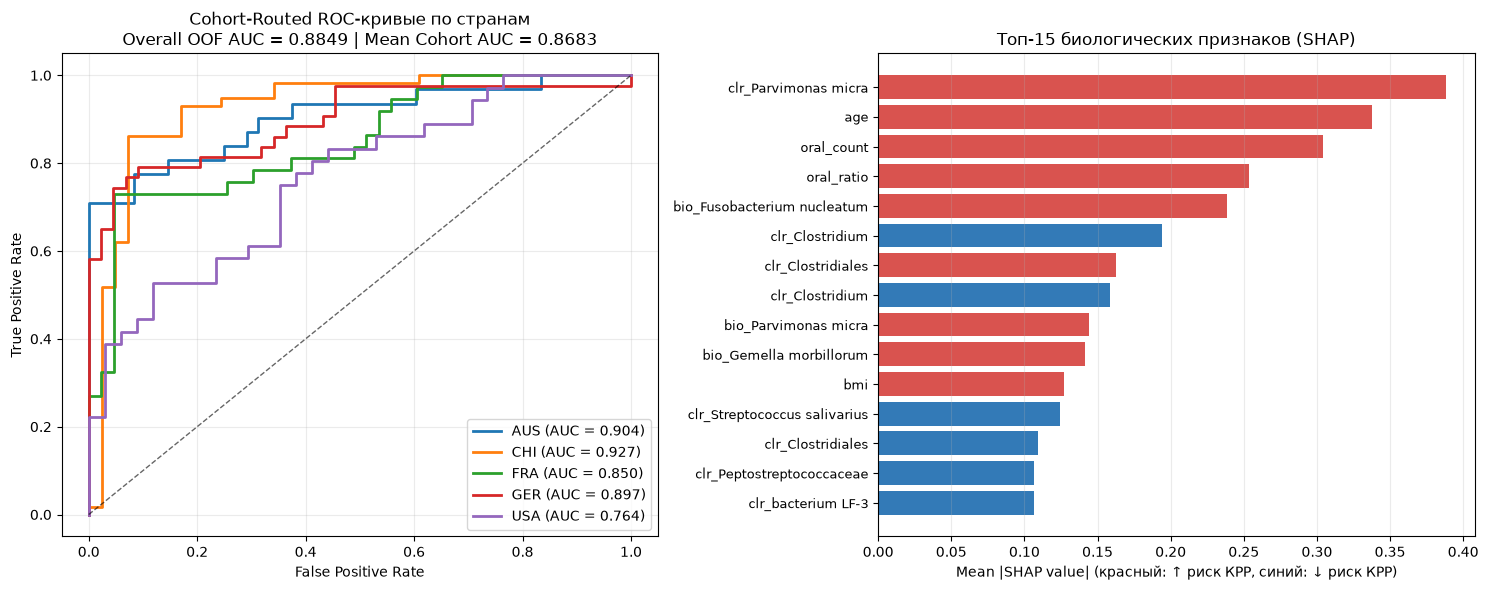

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

ax_roc = axes[0]
cohort_aucs = []
for c in ["AUS", "CHI", "FRA", "GER", "USA"]:
    m = (cohorts == c)
    fpr, tpr, _ = roc_curve(y_train[m], oof_routed[m])
    auc_c = roc_auc_score(y_train[m], oof_routed[m])
    cohort_aucs.append(auc_c)
    ax_roc.plot(fpr, tpr, lw=2, label=f"{c} (AUC = {auc_c:.3f})")

overall_auc = roc_auc_score(y_train, oof_routed)
ax_roc.plot([0, 1], [0, 1], "k--", lw=1, alpha=0.6)
ax_roc.set_title(
    f"Cohort-Routed ROC-кривые по странам\n"
    f"Overall OOF AUC = {overall_auc:.4f} | Mean Cohort AUC = {np.mean(cohort_aucs):.4f}"
)
ax_roc.set_xlabel("False Positive Rate")
ax_roc.set_ylabel("True Positive Rate")
ax_roc.legend(loc="lower right")
ax_roc.grid(alpha=0.25)

ax_imp = axes[1]
cb_inspect = CatBoostClassifier(
    iterations=600, learning_rate=0.025, depth=4, l2_leaf_reg=8,
    rsm=0.75, random_seed=SEED, verbose=False, thread_count=1
)
cb_inspect.fit(X_train_glob, y_train, verbose=False)

feat_names = [
    "log_oral", "log_buty", "log_mucin", "log_fac", "oral_count", "buty_count",
    "richness", "shannon", "simpson", "dysbiosis_oral_buty", "dysbiosis_multi",
    "oral_ratio", "age", "gender_M", "bmi", "age_x_dys", "age_x_oral"
] + [f"bio_{t}" for t in MATCHED_BIO_TERMS]
feat_names += [f"clr_{species_names[i][:28]}" for i in final_taxa_idx]
feat_names += [f"pres_{species_names[i][:28]}" for i in final_taxa_idx]

shap_values = cb_inspect.get_feature_importance(Pool(X_train_glob, y_train), type="ShapValues")[:, :-1]
mean_abs_shap = np.mean(np.abs(shap_values), axis=0)
top_idx = np.argsort(mean_abs_shap)[-15:]

colors = []
for j in top_idx:
    col_x = X_train_glob[:, j]
    col_s = shap_values[:, j]
    corr = np.corrcoef(col_x, col_s)[0, 1] if (np.std(col_x) > 1e-12 and np.std(col_s) > 1e-12) else 0.0
    colors.append("#d9534f" if corr >= 0 else "#337ab7")

ax_imp.barh(range(len(top_idx)), mean_abs_shap[top_idx], color=colors)
ax_imp.set_yticks(range(len(top_idx)))
ax_imp.set_yticklabels([feat_names[j] for j in top_idx], fontsize=9)
ax_imp.set_xlabel("Mean |SHAP value| (красный: ↑ риск КРР, синий: ↓ риск КРР)")
ax_imp.set_title("Топ-15 биологических признаков (SHAP)")
ax_imp.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

## 5. Вывод финальной таблицы предсказаний (Раздел 1)
Ниже выводится таблица предсказаний для `test.csv` (160 образцов, sample_id и label), полностью соответствующая загруженному файлу ответов.


In [5]:
assert len(final_probs) == 160, "Число строк должно быть ровно 160"
assert test_df["sample_id"].is_unique, "sample_id должны быть уникальными"
assert not np.isnan(final_probs).any(), "Предсказания не должны содержать NaN"
assert (final_probs >= 0.0).all() and (final_probs <= 1.0).all(), "Вероятности должны быть в диапазоне [0, 1]"

submission = pd.DataFrame({
    "sample_id": test_df["sample_id"],
    "label": final_probs
})

submission.to_csv("submission.csv", index=False)
print(f"Файл submission.csv успешно сохранён (строк: {len(submission)}).")
print(f"Мин: {final_probs.min():.4f}, Медиана: {np.median(final_probs):.4f}, Макс: {final_probs.max():.4f} | >0.5: {(final_probs >= 0.5).mean():.1%}")

submission

Файл submission.csv успешно сохранён (строк: 160).
Мин: 0.0098, Медиана: 0.4765, Макс: 0.9941 | >0.5: 49.4%


,sample_id,label
0,S0125,0.3059
1,S0242,0.3142
2,S0053,0.0677
3,S0173,0.0803
4,S0453,0.7509
...,...,...
155,S0491,0.8889
156,S0360,0.9131
157,S0192,0.5450
158,S0005,0.9455
